# Tokenizers & English Morphology — Onboarding

**Question:** Do tokenizers split words at the right place less often when adding a suffix changes the spelling?

Run the cells top to bottom. There are **three TODOs** (sections 3, 4 and 6).

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Find the repo root so this works from starter/ or submissions/<username>/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "onboarding").is_dir())
sys.path.append(str(ROOT / "src"))

from onboarding.data import load_morphynet, prepare_suffix_data, balanced_sample
from onboarding.tokenizers import load_tokenizers, tokenize_with_offsets

c:\Users\Deepika Anbalagan\Documents\proj\sanskrit_sandhi\core-member-onboarding\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
None of PyTorch, TensorFlow >= 2.0, or Flax have been found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


## 1. Load the data

Each row has a `source` word, a `morpheme` (the suffix), and the `target` word they form. `suffix_boundary` is the character position where the suffix starts in `target`.

`group` is `concatenative` when `target == source + morpheme` (slow + ly → slowly) and `rewritten` otherwise (happy + ness → happiness).

In [2]:
suffixes = prepare_suffix_data(load_morphynet())
print(suffixes["group"].value_counts())

cols = ["source", "morpheme", "target", "suffix_boundary"]
display(suffixes[suffixes["group"] == "concatenative"][cols].sample(5, random_state=0))
display(suffixes[suffixes["group"] == "rewritten"][cols].sample(5, random_state=0))

group
concatenative    77411
rewritten        39706
Name: count, dtype: int64


,source,morpheme,target,suffix_boundary
7855,confront,er,confronter,8
16081,fluorescent,ly,fluorescently,11
93048,shogun,ite,Shogunite,6
36260,scroll,wise,scrollwise,6
2825,ruth,less,ruthless,4


,source,morpheme,target,suffix_boundary
72784,forbid,able,forbiddable,7
61021,rodomontade,er,rhodomontader,11
113234,bibliophile,ic,bibliophilic,10
4035,obscene,ity,obscenity,6
14587,stuffy,ly,stuffily,6


The `rewritten` label comes from a rough rule, so it isn't perfect ground truth. Note anything that looks odd.

Next, sample 500 words per group. The seed is fixed so everyone gets the same sample.

In [11]:
sample = balanced_sample(suffixes, n_per_group=500, random_state=42)
sample["group"].value_counts()

group
rewritten        500
concatenative    500
Name: count, dtype: int64

## 2. See how tokenizers split words

We compare `bert-base-uncased` and `gpt2`. Each token comes with an **offset** `(start, end)`, which gives the characters of the word it covers.

In [12]:
tokenizers = load_tokenizers()

for word in ["slowly", "happiness"]:
    for name, tok in tokenizers.items():
        out = tokenize_with_offsets(tok, word)
        print(f"{word:>10} {name:>5}: {out['tokens']}  offsets={out['offsets']}")

    slowly  bert: ['slowly']  offsets=[(0, 6)]
    slowly  gpt2: ['slow', 'ly']  offsets=[(0, 4), (4, 6)]
 happiness  bert: ['happiness']  offsets=[(0, 9)]
 happiness  gpt2: ['h', 'appiness']  offsets=[(0, 1), (1, 9)]


## 3. TODO 1: implement `boundary_aligned`

Return `True` if some token starts exactly at `boundary`.

For example, the boundary in `slow|ly` is 4. GPT-2's offsets are `[(0, 4), (4, 6)]`, so a token starts at 4 and the word is aligned.

The checks below pass once your function is right.

In [ ]:
def boundary_aligned(offsets, boundary):
    """offsets: list of (start, end) per token. boundary: where the suffix starts."""
    for i, j in offsets:
        # any token begins where suffix begins  
        if i == boundary:
            return True
        
    return False # no token started at boundary
    
    # raise NotImplementedError


assert boundary_aligned([(0, 4), (4, 6)], 4)      # slow | ly        -> aligned
assert not boundary_aligned([(0, 6)], 4)          # slowly (1 token) -> not aligned
assert not boundary_aligned([(0, 1), (1, 9)], 5)  # h | appiness     -> not aligned (suffix "ness" starts at 5)
print("All checks passed!")

All checks passed!


## 4. TODO 2: run the experiment

For every sampled word and both tokenizers, record whether the boundary aligned and how many tokens the word used.

In [14]:
rows = []
for _, row in sample.iterrows():
    for name, tok in tokenizers.items():
        out = tokenize_with_offsets(tok, row["target"])
        rows.append({
            "word": row["target"],
            "group": row["group"],
            "tokenizer": name,
            "tokens": out["tokens"],
            "aligned": boundary_aligned(out["offsets"], row["suffix_boundary"]),  
            "n_tokens": len(out["tokens"]),
        })

results = pd.DataFrame(rows)
results.head()

,word,group,tokenizer,tokens,aligned,n_tokens
0,frustrater,rewritten,bert,"[fr, ##ust, ##rate, ##r]",False,4
1,frustrater,rewritten,gpt2,"[fr, ust, r, ater]",False,4
2,sporophorous,rewritten,bert,"[sp, ##oro, ##ph, ##orous]",False,4
3,sporophorous,rewritten,gpt2,"[s, por, oph, orous]",False,4
4,implication,rewritten,bert,[implication],False,1


## 5. Compare the groups

`aligned` is the fraction of words where a token starts at the suffix boundary. `n_tokens` is the average number of tokens per word.

In [15]:
summary = results.groupby(["tokenizer", "group"])[["aligned", "n_tokens"]].mean().round(3)
summary

aligned  n_tokens
tokenizer group                           
bert      concatenative    0.692     2.704
          rewritten        0.188     3.024
gpt2      concatenative    0.622     3.064
          rewritten        0.314     3.090

## 6. TODO 3: plot it

Make one plot comparing the alignment rate of the two groups for each tokenizer. A grouped bar chart works well (hint: `summary["aligned"].unstack().plot.bar()`). Label the axes and add a title.

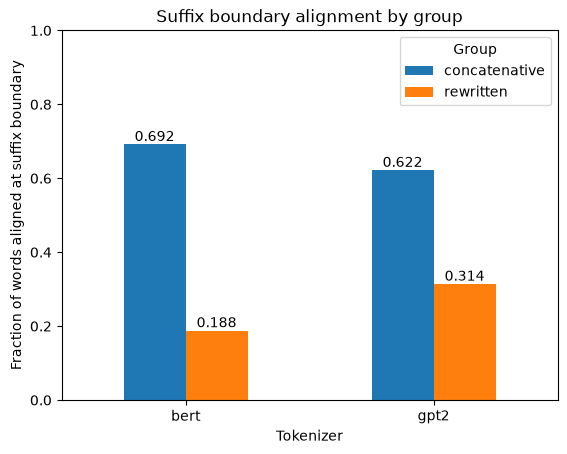

In [22]:
ax = summary["aligned"].unstack().plot.bar(rot=0)
ax.set_xlabel("Tokenizer")
ax.set_ylabel("Fraction of words aligned at suffix boundary")
ax.set_title("Suffix boundary alignment by group")
ax.set_ylim(0, 1)
ax.legend(title="Group")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f")


plt.savefig("alignment.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Look at the misses

The averages are easier to interpret once you've seen real examples. Below are some rewritten words where the boundary was missed. Use one of them in `findings.md`.

In [20]:
misses = results[(results["group"] == "rewritten") & ~results["aligned"]]
misses[["word", "tokenizer", "tokens"]].sample(10, random_state=0)

,word,tokenizer,tokens
1309,clarifiable,gpt2,"[cl, ar, ifiable]"
263,lazily,gpt2,"[l, az, ily]"
679,satiation,gpt2,"[sat, iation]"
58,marbly,bert,"[mar, ##bly]"
1652,comitology,bert,"[com, ##ito, ##logy]"
1473,centenarian,gpt2,"[cent, en, arian]"
1908,retired,bert,[retired]
20,authorizer,bert,"[author, ##izer]"
1302,phantasmagorial,bert,"[ph, ##anta, ##sma, ##gor, ##ial]"
438,graticulation,bert,"[gr, ##atic, ##ulation]"


## 8. Write it up

Fill in `findings.md` with three short answers. Then follow **Submitting** in the README.